# Predicción de viajes de taxi por zona y hora
**Vicente Yagello · Big Data TI3025 · INACAP**

Ejecución histórica en BigQuery: enero–marzo de 2022. Ejecutar las celdas en orden. El modo normal revisa resultados reales exportados sin credenciales ni consumo cloud. El informe explica arquitectura, decisiones y limitaciones.

## Arquitectura y continuidad

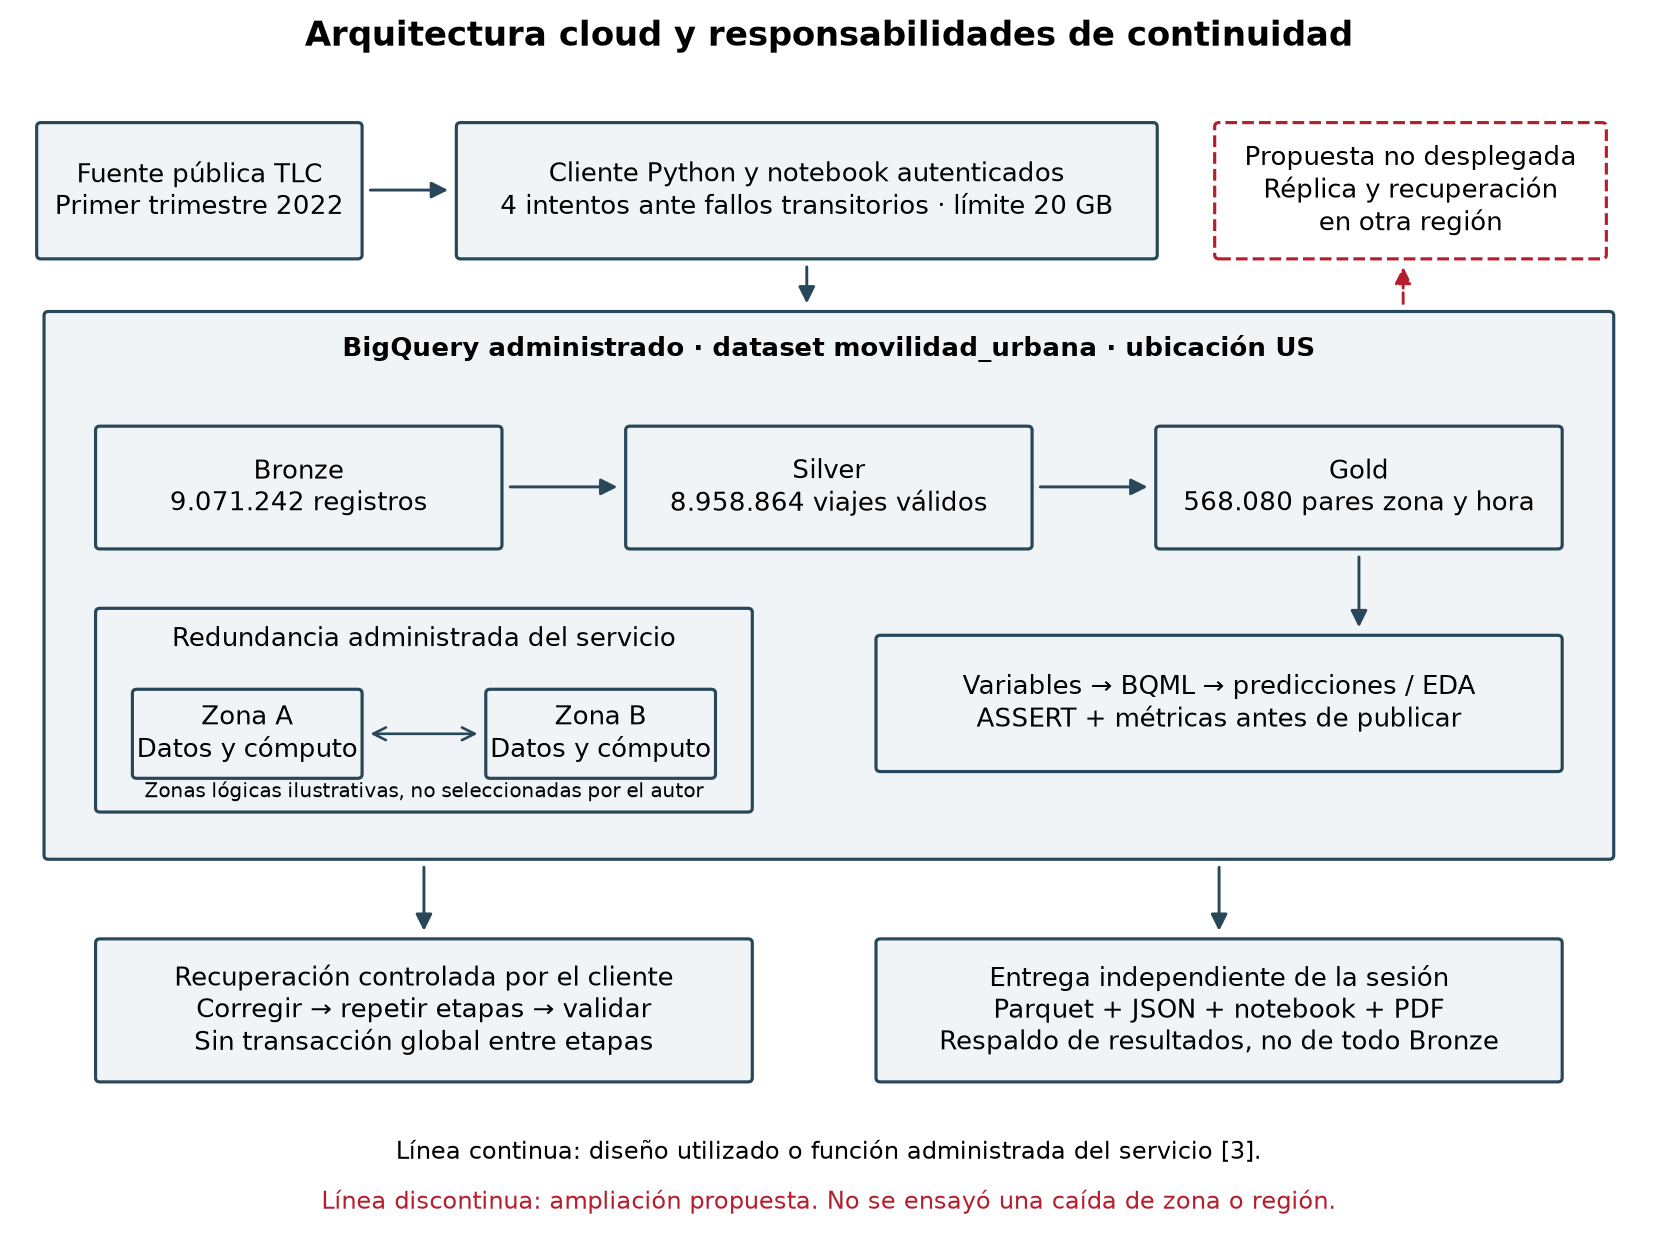

La redundancia zonal y el cómputo distribuido son funciones administradas de BigQuery. Los reintentos y la reconstrucción por etapas pertenecen al cliente. La réplica regional es una propuesta no desplegada; no se simularon caídas de zona ni región.

In [1]:
import importlib.util
import json
import pathlib
import subprocess
import sys
import urllib.request

def disponible(modulo):
    try:
        return importlib.util.find_spec(modulo) is not None
    except ModuleNotFoundError:
        return False

paquetes = {"pandas": "pandas>=2.2,<4", "pyarrow": "pyarrow>=18", "matplotlib": "matplotlib>=3.9", "google.cloud.bigquery": "google-cloud-bigquery>=3.30"}
faltantes = [paquete for modulo, paquete in paquetes.items() if not disponible(modulo)]
if faltantes:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes], check=True)
raiz = pathlib.Path.cwd()
for archivo in ["resultados.json", "demanda_horaria.parquet", "pipeline.py", "configuracion.json"]:
    if not (raiz / archivo).exists():
        urllib.request.urlretrieve("https://raw.githubusercontent.com/c3cla/bigdata-ev2-vicente/main/" + archivo, raiz / archivo)
print("Archivos disponibles en", raiz)


Archivos disponibles en C:\Users\vicen\Desktop\trabajo big data\entrega_simple


## Reconstrucción opcional
`RECONSTRUIR = False` conserva los resultados entregados. Activarlo reemplaza las tablas y el modelo de movilidad_urbana en el proyecto elegido y consume sus cuotas. En Colab se solicitará autenticación Google; fuera de Colab usar previamente `gcloud auth application-default login`. No se incluyen claves.

In [2]:
RECONSTRUIR = False
PROYECTO = "round-pen-449819-s1"
if RECONSTRUIR:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "google-cloud-bigquery>=3.30", "db-dtypes>=1.3"], check=True)
    if importlib.util.find_spec("google.colab"):
        from google.colab import auth
        auth.authenticate_user()
    subprocess.run([sys.executable, str(raiz / "pipeline.py"), "--proyecto", PROYECTO], check=True)
else:
    print("Demostración: resultados exportados de BigQuery, sin reconstrucción.")


Demostración: resultados exportados de BigQuery, sin reconstrucción.


## Calidad y análisis descriptivo
Bronze conserva originales; Silver valida fecha y zona; Gold incluye las horas sin viajes. Importes negativos se auditan, pero no se usan para predecir. El respaldo usa Parquet/Snappy. Las tablas cloud usan particiones enteras y clustering temporal.

Celdas sin viajes: 64.73%


Fallback to a different backend


,filas_originales,fecha_nula,fuera_periodo,zona_invalida,distancia_negativa,importe_negativo,fechas_invertidas,filas_limpias
0,9071242,0,110,112268,0,48588,4685,8958864


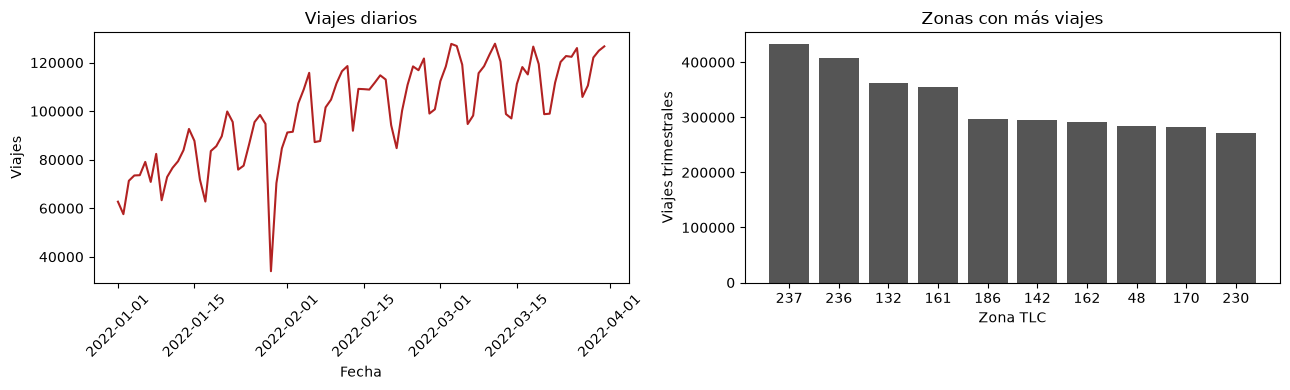

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.core.pylabtools import select_figure_formats

select_figure_formats(get_ipython(), {"png"})

resultados = json.loads((raiz / "resultados.json").read_text(encoding="utf-8"))
demanda = pd.read_parquet(raiz / "demanda_horaria.parquet")
demanda["hora"] = pd.to_datetime(demanda["hora"], utc=True)
display(pd.DataFrame(resultados["calidad"]))
diario = pd.DataFrame(resultados["diario"]).sort_values("fecha")
zonas = pd.DataFrame(resultados["zonas"]).nlargest(10, "viajes")
figura, ejes = plt.subplots(1, 2, figsize=(13, 4))
ejes[0].plot(pd.to_datetime(diario.fecha), diario.viajes, color="#b22222")
ejes[0].set(title="Viajes diarios", ylabel="Viajes", xlabel="Fecha")
ejes[0].tick_params(axis="x", rotation=45)
ejes[1].bar(zonas.zona_id.astype(str), zonas.viajes, color="#555555")
ejes[1].set(title="Zonas con más viajes", xlabel="Zona TLC", ylabel="Viajes trimestrales")
figura.tight_layout()
display(figura)
plt.close(figura)
print(f"Celdas sin viajes: {(demanda.viajes == 0).mean():.2%}")


## Modelo y comparación
Regresión lineal regularizada en BigQuery ML. Variables: rezagos de 1, 24 y 168 horas, media de las 24 horas anteriores, ciclo horario, zona y día semanal. Entrenamiento hasta 15 de febrero; validación 16–28 de febrero; prueba en marzo. La primera semana forma rezagos. Modelo fijo con evaluación secuencial una hora adelante, no un pronóstico mensual anticipado.

In [4]:
display(pd.DataFrame(resultados["distribucion"]))
metricas = pd.DataFrame(resultados["metricas"]).sort_values("rmse")
display(metricas.round(4))
regresion = metricas[metricas.modelo == "Regresion lineal BQML"].iloc[0]
semanal = metricas[metricas.modelo == "Estacional semana anterior"].iloc[0]
print(f"Reducción de RMSE frente a referencia semanal: {100 * (1 - regresion.rmse / semanal.rmse):.2f}%")
print("La referencia semanal obtiene mejor MAE y WAPE: no hay mejora uniforme.")


Reducción de RMSE frente a referencia semanal: 8.80%
La referencia semanal obtiene mejor MAE y WAPE: no hay mejora uniforme.


,conjunto,filas,viajes,primera_hora,ultima_hora
0,entrenamiento,246168,3494152,2022-01-08T00:00:00Z,2022-02-15T23:00:00Z
1,validacion,82056,1395356,2022-02-16T00:00:00Z,2022-02-28T23:00:00Z
2,prueba,195672,3580661,2022-03-01T00:00:00Z,2022-03-31T23:00:00Z


,modelo,filas_evaluadas,mae,rmse,wape,r2
1,Regresion lineal BQML,195672,3.3011,9.8085,18.0397,0.9678
3,Estacional semana anterior,195672,3.1860,10.7548,17.4106,0.9613
2,Persistencia ultima hora,195672,4.4157,14.2699,24.1305,0.9319
0,Estacional dia anterior,195672,4.6881,17.1530,25.6189,0.9017


## Diagnóstico por zona y volumen
Las métricas por zona se calcularon en BigQuery sobre las 744 horas de marzo. Los cuartiles siguientes son un diagnóstico retrospectivo según el volumen de prueba; no se utilizaron para seleccionar variables ni ajustar el modelo. El WAPE del grupo se recalcula desde errores absolutos y viajes, no promediando porcentajes por zona.

In [5]:
errores = pd.DataFrame(resultados["errores_zona"])
display(errores.nlargest(6, "viajes")[["zona_id", "filas", "viajes", "mae", "rmse", "wape"]].round(3))
errores["grupo"] = pd.qcut(errores.viajes.rank(method="first"), 4, labels=["Q1 menor volumen", "Q2", "Q3", "Q4 mayor volumen"])
diagnostico = []
for nombre, grupo in errores.groupby("grupo", observed=True):
    diagnostico.append({"grupo": nombre, "zonas": len(grupo), "viajes": grupo.viajes.sum(),
                        "mae": (grupo.mae * grupo.filas).sum() / grupo.filas.sum(),
                        "rmse": ((grupo.rmse ** 2 * grupo.filas).sum() / grupo.filas.sum()) ** 0.5,
                        "wape": 100 * (grupo.mae * grupo.filas).sum() / grupo.viajes.sum()})
display(pd.DataFrame(diagnostico).round(3))
print("Zonas sin viajes en marzo:", int((errores.viajes == 0).sum()))
print("En zonas de volumen mínimo, errores absolutos pequeños pueden producir WAPE muy alto.")
print("No se recomienda uso uniforme: evaluar alternativas para conteos escasos con datos de entrenamiento y validación.")


Zonas sin viajes en marzo: 8
En zonas de volumen mínimo, errores absolutos pequeños pueden producir WAPE muy alto.
No se recomienda uso uniforme: evaluar alternativas para conteos escasos con datos de entrenamiento y validación.


,zona_id,filas,viajes,mae,rmse,wape
196,237,744,168295,27.615,37.787,12.208
108,132,744,152728,37.346,47.565,18.193
200,161,744,152353,29.108,40.680,14.215
195,236,744,152289,27.688,39.161,13.527
201,162,744,122271,22.088,29.599,13.440
42,186,744,118396,24.776,33.779,15.569


,grupo,zonas,viajes,mae,rmse,wape
0,Q1 menor volumen,66,1195,0.431,0.684,1771.171
1,Q2,66,6608,0.497,0.792,369.290
2,Q3,65,34385,0.838,1.334,117.912
3,Q4 mayor volumen,66,3538473,11.401,19.507,15.821


## Evidencia del pipeline y seguimiento
Los registros conservan también fallos: DONE significa trabajo terminado, no necesariamente exitoso. El éxito requiere ausencia de error. La bitácora resume hitos reales de la ejecución original; los identificadores completos están en el JSON. El procesamiento y el entrenamiento fueron cloud; las tablas siguientes solo presentan exportaciones.

In [6]:
display(pd.DataFrame(resultados["almacenamiento"]))
if "auditoria" in resultados:
    display(pd.DataFrame(resultados["auditoria"]["bitacora_cloud"])[["fecha_hora_local", "actividad", "resultado", "job_id"]])
else:
    display(pd.DataFrame(resultados["ejecuciones"]))


,tabla,filas,bytes_tabla
0,bronze_viajes,9071242,1874033402
1,control_calidad,1,64
2,eda_diario,90,1440
3,eda_horario,168,4032
4,eda_zonas,263,4208
5,features_demanda,523896,45534768
6,gold_demanda,568080,13633920
7,metricas,4,262
8,modelo_demanda,9,48555
9,predicciones,195672,10957632


,fecha_hora_local,actividad,resultado,job_id
0,2026-10-18T21:14:19.619000-03:00,Ingesta inicial,Finalizado sin error,job_vQDzzrB_gPPoG8M2SqJCT2hXmZr6
1,2026-10-18T21:15:18.587000-03:00,Primeras transformaciones,Finalizado sin error,job_YnKd3wuns_41WgRGLjtT-WygWbVH
2,2026-10-18T21:16:28.956000-03:00,Entrenamiento fallido: sin filas,Error registrado,job_V3RJ9RFKw-WBW-pqXLjUTN4woP7p
3,2026-10-18T21:20:33.366000-03:00,Reconstrucción con rangos enteros,Finalizado sin error,job_WfmBy1YJaZXc-JMkkKo8h-RW7bj2
4,2026-10-18T21:21:09.639000-03:00,Modelo y métricas correctos,Finalizado sin error,job_lL6oRnAo62tXxyJxVeEp9NbJBZl2
5,2026-10-18T21:22:11.380000-03:00,Cinco controles SQL,Finalizado sin error,job_M7nz1OdK7f1PMx6aTCxekZSWlfeH
6,2026-10-18T21:24:23.827000-03:00,Metadatos sin permiso,Error registrado,job_0ksfV0eUFMdEppeC8RI7sEIuMBl8
7,2026-10-18T21:25:30.419000-03:00,Exportación analítica,Finalizado sin error,job_-goNz7pKOg-vh5qKK8i8093S1bh6


## Prototipo
Elegir zona 132, 161 o 237 y una hora exacta del 1 al 7 de marzo. Son predicciones cloud exportadas; las métricas anteriores incluyen las 263 zonas durante todo marzo.

<ipython-input-7-0cc927b61a5a>:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(seleccion.round(3))


,hora,zona_id,viajes,rezago_1,rezago_24,rezago_168,predicted_viajes,error_absoluto
234,2022-03-03 18:00:00+00:00,161,395,464,486,458,482.386,87.386


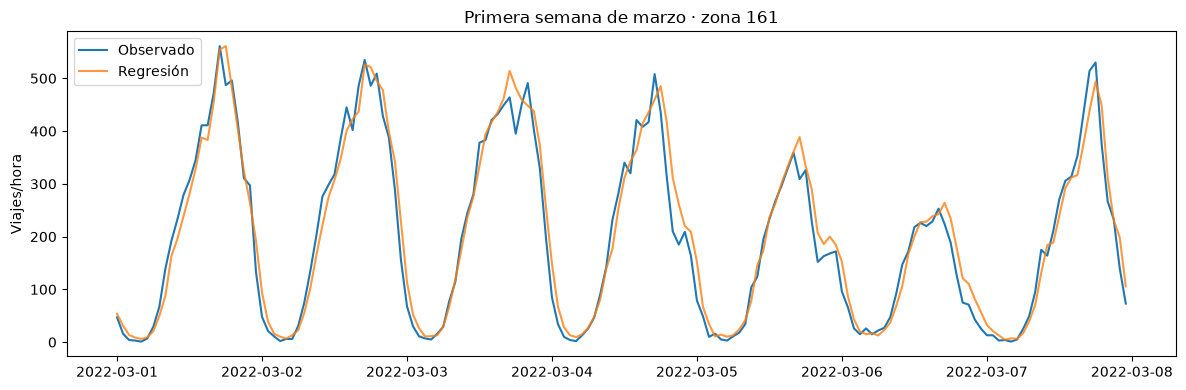

In [7]:
ZONA = 161
HORA = "2022-03-03 18:00:00+00:00"
muestra = pd.DataFrame(resultados["muestra_predicciones"])
muestra["hora"] = pd.to_datetime(muestra.hora, utc=True)
seleccion = muestra[(muestra.zona_id == ZONA) & (muestra.hora == pd.Timestamp(HORA))].copy()
if seleccion.empty:
    raise ValueError("Usar zona 132, 161 o 237 y una hora exacta del 1 al 7 de marzo")
seleccion["error_absoluto"] = (seleccion.viajes - seleccion.predicted_viajes).abs()
display(seleccion.round(3))
serie = muestra[muestra.zona_id == ZONA].sort_values("hora")
figura, eje = plt.subplots(figsize=(12, 4))
eje.plot(serie.hora, serie.viajes, label="Observado")
eje.plot(serie.hora, serie.predicted_viajes, label="Regresión", alpha=0.8)
eje.set(title=f"Primera semana de marzo · zona {ZONA}", ylabel="Viajes/hora")
eje.legend()
figura.tight_layout()
display(figura)
plt.close(figura)


## Comprobaciones
Se verifica conservación, grilla completa, rezagos y media móvil contra el histórico, separación cronológica y universo común de evaluación. Los viajes realizados no miden demanda insatisfecha; el trimestre no representa otras ciudades ni años. La disponibilidad temporal de los datos impide presentar este prototipo como despacho en tiempo real.

In [8]:
assert len(demanda) == 263 * 90 * 24
assert not demanda.duplicated(["zona_id", "hora"]).any()
assert (demanda.groupby("zona_id").size() == 2160).all()
assert demanda.viajes.sum() == resultados["calidad"][0]["filas_limpias"]
assert len(metricas) == 4 and (metricas.filas_evaluadas == 263 * 31 * 24).all()
assert (metricas[["mae", "rmse", "wape"]] >= 0).all().all()
assert len(errores) == 263 and (errores.filas == 744).all()
assert errores.viajes.sum() == demanda.loc[demanda.hora >= "2022-03-01", "viajes"].sum()
assert abs((errores.mae * errores.filas).sum() / errores.filas.sum() - regresion.mae) < 1e-7
assert abs(((errores.rmse ** 2 * errores.filas).sum() / errores.filas.sum()) ** 0.5 - regresion.rmse) < 1e-7
rangos = pd.DataFrame(resultados["distribucion"]).set_index("conjunto")
assert pd.Timestamp(rangos.loc["entrenamiento", "ultima_hora"]) < pd.Timestamp(rangos.loc["validacion", "primera_hora"])
assert pd.Timestamp(rangos.loc["validacion", "ultima_hora"]) < pd.Timestamp(rangos.loc["prueba", "primera_hora"])
historial = demanda.set_index(["zona_id", "hora"])["viajes"]
variables = pd.DataFrame(resultados["muestra_variables"])
variables["hora"] = pd.to_datetime(variables.hora, utc=True)
assert len(variables) > 0
for fila in variables.itertuples():
    for retraso in (1, 24, 168):
        assert getattr(fila, f"rezago_{retraso}") == historial.loc[(fila.zona_id, fila.hora - pd.Timedelta(hours=retraso))]
    anteriores = pd.date_range(fila.hora - pd.Timedelta(hours=24), periods=24, freq="h")
    esperado = historial.loc[[(fila.zona_id, hora) for hora in anteriores]].mean()
    assert abs(fila.media_24h - esperado) < 1e-7
print("Integridad, conservación, separación temporal y 144 muestras de variables verificadas.")


Integridad, conservación, separación temporal y 144 muestras de variables verificadas.


## Pruebas unitarias de tolerancia del cliente
Se inyectan excepciones en un cliente simulado, sin ejecutar consultas, usar credenciales ni consumir cuotas. Se comprueban recuperación tras un error transitorio, agotamiento de cuatro intentos y propagación inmediata de un error SQL. Estas pruebas no representan una caída real de zona o región.

In [9]:
from unittest.mock import MagicMock, patch, call
from google.api_core.exceptions import ServiceUnavailable, BadRequest

espacio = {"__file__": str(raiz / "pipeline.py"), "__name__": "pipeline_verificado"}
exec(compile((raiz / "pipeline.py").read_text(encoding="utf-8"), str(raiz / "pipeline.py"), "exec"), espacio)
ejecutar_consulta = espacio["ejecutar_consulta"]
configuracion = json.loads((raiz / "configuracion.json").read_text(encoding="utf-8"))
trabajo = MagicMock()
trabajo.result.return_value = [{"control": "correcto"}]
cliente = MagicMock()
cliente.query.side_effect = [ServiceUnavailable("fallo simulado"), trabajo]
with patch.object(espacio["time"], "sleep") as espera:
    trabajo_recibido, filas = ejecutar_consulta(cliente, "SELECT 1", configuracion)
    assert cliente.query.call_count == 2 and filas == [{"control": "correcto"}]
    espera.assert_called_once_with(1)
    assert cliente.query.call_args.kwargs["job_config"].maximum_bytes_billed == 20000000000
cliente = MagicMock()
cliente.query.side_effect = ServiceUnavailable("fallo simulado")
with patch.object(espacio["time"], "sleep") as espera:
    try:
        ejecutar_consulta(cliente, "SELECT 1", configuracion)
    except ServiceUnavailable:
        pass
    else:
        raise AssertionError("El fallo definitivo debe propagarse")
    assert cliente.query.call_count == 4
    assert espera.call_args_list == [call(1), call(2), call(4)]
cliente = MagicMock()
cliente.query.side_effect = BadRequest("SQL inválido simulado")
with patch.object(espacio["time"], "sleep") as espera:
    try:
        ejecutar_consulta(cliente, "SELECT", configuracion)
    except BadRequest:
        pass
    else:
        raise AssertionError("El error SQL debe propagarse sin reintento")
    assert cliente.query.call_count == 1 and not espera.called
print("Tres pruebas unitarias del cliente aprobadas; no se realizaron consultas cloud.")


Tres pruebas unitarias del cliente aprobadas; no se realizaron consultas cloud.
